In [1]:
import numpy as np, pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

seeds = [105, 106, 107, 108, 109]
R = {s: pd.read_csv(f"../outputs/tables/harm_seed{s}_v3_noapr.csv") for s in seeds}

def hc(diff, se, eps):
    diff, se = np.asarray(diff, float), np.asarray(se, float)
    z = np.where(se > 0, (diff - eps) / np.where(se > 0, se, 1), -np.inf)
    return int(multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0].sum())

rows = []
for eps in [0.0, 0.005, 0.01, 0.02]:
    meths = {"pooled": "b1.0", "fedprox": "fedprox", "finetune": "finetune"}
    if eps > 0:
        meths.update({"certified pooled": f"cert{eps}", "certified finetune": f"certft{eps}"})
    for name, m in meths.items():
        c = [hc(R[s][f"{m}__diff"], R[s][f"{m}__se"], eps) for s in seeds]
        rows.append((eps, name, np.mean(c), min(c), max(c),
                     np.mean([(R[s][f"{m}__diff"] > eps).mean() for s in seeds]),
                     np.mean([R[s][f"{m}__diff"].max() for s in seeds]),
                     np.mean([R[s][f"{m}__diff"].mean() for s in seeds]),
                     np.mean([(R[s][f"{m}__auroc"] - R[s]["local__auroc"]).mean() for s in seeds])))
print(pd.DataFrame(rows, columns=["eps", "method", "harmed_mean", "min", "max", "raw_share_above_eps",
                                  "worst_regret", "mean_loss_diff", "auroc_gain"]).round(5).to_string())

print("\nhospitals given a non-local model (mean over seeds)")
for eps in [0.005, 0.01, 0.02]:
    print(eps, "pooled sequence:", np.mean([(R[s][f"sel_eps{eps}"] > 0).sum() for s in seeds]),
          " fine-tuned sequence:", np.mean([(R[s][f"sel_ft{eps}"] > 0).sum() for s in seeds]))

      eps              method  harmed_mean  min  max  raw_share_above_eps  worst_regret  mean_loss_diff  auroc_gain
0   0.000              pooled         15.4   14   18              0.67778       0.02354         0.00249     0.00276
1   0.000             fedprox         20.8   19   22              0.76190       0.02676         0.00361     0.00247
2   0.000            finetune          0.8    0    2              0.39048       0.00696        -0.00048     0.00447
3   0.005              pooled          0.2    0    1              0.24444       0.02354         0.00249     0.00276
4   0.005             fedprox          2.0    1    3              0.31111       0.02676         0.00361     0.00247
5   0.005            finetune          0.0    0    0              0.01111       0.00696        -0.00048     0.00447
6   0.005    certified pooled          0.0    0    0              0.00000       0.00215         0.00006     0.00008
7   0.005  certified finetune          0.0    0    0              0.0000

                            method  harmed_eps0  harmed_beyond_0.01  significantly_better  raw_share_worse  worst_regret  mean_loss_diff  auroc_gain  auprc_gain
0                           Pooled         15.4                 0.2                   0.2          0.67778       0.02354         0.00249     0.00276    -0.00902
1                          FedProx         20.8                 0.2                   0.2          0.76190       0.02676         0.00361     0.00247    -0.01486
2                           FedAvg         23.2                 1.8                   0.2          0.80794       0.03571         0.00628     0.00207    -0.01816
3           Pooled + recalibration          4.4                 0.0                   0.2          0.47143       0.01742         0.00022     0.00276    -0.00902
4                       Blend 0.25          0.0                 0.0                   1.4          0.26349       0.00215        -0.00060     0.00609     0.00247
5                      Fine-tuning

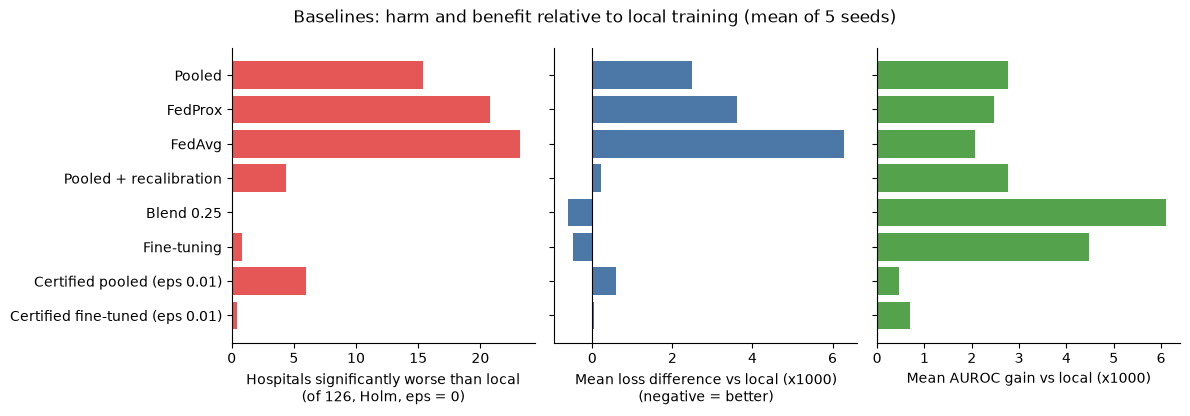

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
M = [("Pooled", "b1.0"), ("FedProx", "fedprox"), ("FedAvg", "fedavg"), ("Pooled + recalibration", "recal"),
     ("Blend 0.25", "b0.25"), ("Fine-tuning", "finetune"),
     ("Certified pooled (eps 0.01)", "cert0.01"), ("Certified fine-tuned (eps 0.01)", "certft0.01")]
rows = []
for name, m in M:
    h0, hE, sb, raw, reg, dl, au, ap = [], [], [], [], [], [], [], []
    for s in seeds:
        r = R[s]
        h0.append(hc(r[f"{m}__diff"], r[f"{m}__se"], 0.0)); hE.append(hc(r[f"{m}__diff"], r[f"{m}__se"], 0.01))
        z = np.where(r[f"{m}__se"] > 0, r[f"{m}__diff"] / np.where(r[f"{m}__se"] > 0, r[f"{m}__se"], 1), 0.0)
        sb.append(int(multipletests(stats.norm.cdf(z), alpha=0.05, method="holm")[0].sum()))
        raw.append((r[f"{m}__diff"] > 0).mean()); reg.append(r[f"{m}__diff"].max()); dl.append(r[f"{m}__diff"].mean())
        au.append((r[f"{m}__auroc"] - r["local__auroc"]).mean()); ap.append((r[f"{m}__auprc"] - r["local__auprc"]).mean())
    rows.append({"method": name, "harmed_eps0": np.mean(h0), "harmed_beyond_0.01": np.mean(hE), "significantly_better": np.mean(sb),
                 "raw_share_worse": np.mean(raw), "worst_regret": np.mean(reg), "mean_loss_diff": np.mean(dl),
                 "auroc_gain": np.mean(au), "auprc_gain": np.mean(ap)})
T = pd.DataFrame(rows)
T.to_csv("../outputs/tables/T11_baselines_seeds105-109.csv", index=False)
print(T.round(5).to_string())

fig, ax = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
y_ = np.arange(len(T))[::-1]
ax[0].barh(y_, T["harmed_eps0"], color="#E45756"); ax[0].set_xlabel("Hospitals significantly worse than local\n(of 126, Holm, eps = 0)")
ax[1].barh(y_, T["mean_loss_diff"] * 1000, color="#4C78A8"); ax[1].axvline(0, c="k", lw=0.8); ax[1].set_xlabel("Mean loss difference vs local (x1000)\n(negative = better)")
ax[2].barh(y_, T["auroc_gain"] * 1000, color="#54A24B"); ax[2].axvline(0, c="k", lw=0.8); ax[2].set_xlabel("Mean AUROC gain vs local (x1000)")
ax[0].set_yticks(y_); ax[0].set_yticklabels(T["method"])
fig.suptitle("Baselines: harm and benefit relative to local training (mean of 5 seeds)")
plt.tight_layout(); plt.savefig("../outputs/figures/fig14_baselines.png", dpi=300); plt.savefig("../outputs/figures/fig14_baselines.pdf"); plt.show()

In [3]:
import numpy as np, pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

seeds = [110, 111, 112, 113, 114]
C = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv") for s in seeds}
pairs = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]

def loss_harm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return int(multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0].sum())

rows = []
for eps, delta in pairs:
    methods = {"pooled (unclipped)": "pool_full", "fine-tuning (unclipped)": "ft_full",
               "always pooled, clipped": "pool_b1.0", "always fine-tuned, clipped": "ft_b1.0",
               "certified pooled": f"cert_pool_e{eps}_d{delta}", "certified fine-tuned": f"cert_ft_e{eps}_d{delta}"}
    for name, pre in methods.items():
        L, Cs, P, ND, DL, AU = [], [], [], [], [], []
        for s in seeds:
            r = C[s]
            L.append(loss_harm(r, pre, eps)); Cs.append(int((r[f"{pre}__gaplb"] > delta).sum()))
            P.append(int((r[f"{pre}__gapmax"] > delta).sum()))
            DL.append(r[f"{pre}__diff"].mean()); AU.append((r[f"{pre}__auroc"] - r["local__auroc"]).mean())
            if "cert_" in pre:
                ND.append(int((r[f"{pre}__blend"] > 0).sum()))
        rows.append((eps, delta, name, np.mean(L), max(L), np.mean(Cs), max(Cs), np.mean(P),
                     np.mean(ND) if ND else np.nan, np.mean(DL), np.mean(AU)))
T = pd.DataFrame(rows, columns=["eps", "delta", "method", "loss_harm_mean", "loss_harm_max", "cal_harm_mean", "cal_harm_max",
                                "cal_point_above", "nonlocal", "mean_loss_diff", "auroc_gain"])
T.to_csv("../outputs/tables/T11b_certificate_seeds110-114.csv", index=False)
print(T.round(5).to_string())

g = []
for src in ("pool", "ft"):
    for eps in [0.005, 0.01, 0.02]:
        for delta in [0.01, 0.015, 0.02]:
            pre = f"cert_{src}_e{eps}_d{delta}"
            g.append((src, eps, delta, np.mean([(C[s][f"{pre}__blend"] > 0).sum() for s in seeds]),
                      np.mean([C[s][f"{pre}__diff"].mean() for s in seeds]),
                      max(loss_harm(C[s], pre, eps) for s in seeds), max(int((C[s][f"{pre}__gaplb"] > delta).sum()) for s in seeds)))
G = pd.DataFrame(g, columns=["sequence", "eps", "delta", "nonlocal", "mean_loss_diff", "max_loss_harm", "max_cal_harm"])
G.to_csv("../outputs/tables/T10b_certificate_grid.csv", index=False)
print(G.round(5).to_string())

      eps  delta                      method  loss_harm_mean  loss_harm_max  cal_harm_mean  cal_harm_max  cal_point_above  nonlocal  mean_loss_diff  auroc_gain
0   0.005  0.010          pooled (unclipped)             0.6              1            4.8             6             68.8       NaN         0.00289     0.00053
1   0.005  0.010     fine-tuning (unclipped)             0.0              0            0.0             0              6.8       NaN        -0.00035     0.00350
2   0.005  0.010      always pooled, clipped             0.2              1            2.4             3             61.6       NaN         0.00075     0.00436
3   0.005  0.010  always fine-tuned, clipped             0.0              0            0.0             0              5.2       NaN        -0.00050     0.00366
4   0.005  0.010            certified pooled             0.0              0            0.0             0              0.0      17.0         0.00001     0.00021
5   0.005  0.010        certified fine-t

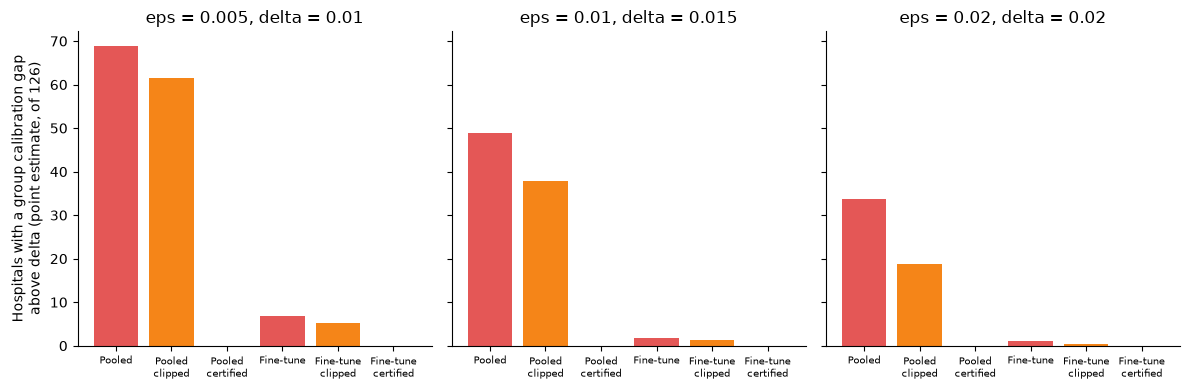

C:\Users\HP\AppData\Local\Temp\ipykernel_75104\25647601.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  big = pd.concat([C[s].assign(seed=s) for s in seeds])
C:\Users\HP\AppData\Local\Temp\ipykernel_75104\25647601.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  big = pd.concat([C[s].assign(seed=s) for s in seeds])
C:\Users\HP\AppData\Local\Temp\ipykernel_75104\25647601.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.

ValueError: cannot reindex on an axis with duplicate labels

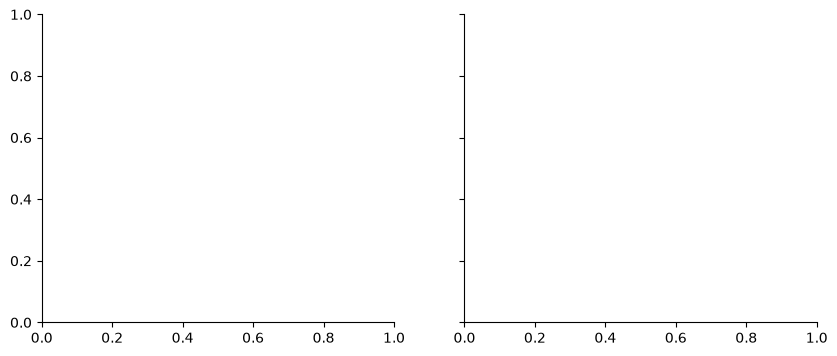

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]
C = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv") for s in seeds}
T = pd.read_csv("../outputs/tables/T11b_certificate_seeds110-114.csv")
def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

# Clipping ablation
order = ["pooled (unclipped)", "always pooled, clipped", "certified pooled",
         "fine-tuning (unclipped)", "always fine-tuned, clipped", "certified fine-tuned"]
cols = ["#E45756", "#F58518", "#54A24B"] * 2
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for a, (eps, delta) in zip(ax, [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]):
    t = T[(T.eps == eps) & (T.delta == delta)].set_index("method").loc[order]
    a.bar(range(6), t["cal_point_above"], color=cols)
    a.set_xticks(range(6)); a.set_xticklabels(["Pooled", "Pooled\nclipped", "Pooled\ncertified", "Fine-tune", "Fine-tune\nclipped", "Fine-tune\ncertified"], fontsize=7)
    a.set_title(f"eps = {eps}, delta = {delta}")
ax[0].set_ylabel("Hospitals with a group calibration gap\nabove delta (point estimate, of 126)")
save("figA_clipping_ablation")

# F11: chosen blend by hospital size
big = pd.concat([C[s].assign(seed=s) for s in seeds])
big["size_q"] = pd.qcut(big["n_train"], 4, labels=["Smallest", "Q2", "Q3", "Largest"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, src, title in zip(ax, ["pool", "ft"], ["Pooled sequence", "Fine-tuned sequence"]):
    tab = pd.crosstab(big["size_q"], big[f"cert_{src}_e0.01_d0.015__blend"], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=a, colormap="viridis", legend=False)
    a.set_title(title + "\n(eps 0.01, delta 0.015)"); a.set_xlabel("Hospital size quartile"); a.tick_params(axis="x", rotation=0)
ax[0].set_ylabel("Share of hospital-seeds"); ax[1].legend(title="Blend weight", frameon=False, fontsize=8)
save("fig11_chosen_blend")

# F12: price of no harm over the 3 x 3 grid
rows = []
for src in ("pool", "ft"):
    for eps in [0.005, 0.01, 0.02]:
        for delta in [0.01, 0.015, 0.02]:
            pre = f"cert_{src}_e{eps}_d{delta}"
            rows.append((src, eps, delta, np.mean([(C[s][f"{pre}__blend"] > 0).sum() for s in seeds]),
                         1000 * np.mean([C[s][f"{pre}__diff"].mean() for s in seeds]),
                         1000 * np.mean([(C[s][f"{pre}__auroc"] - C[s]["local__auroc"]).mean() for s in seeds])))
P = pd.DataFrame(rows, columns=["sequence", "eps", "delta", "nonlocal", "loss_x1000", "auroc_x1000"])
P.to_csv("../outputs/tables/F12_price_of_no_harm_grid.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ecol = {0.005: "#4C78A8", 0.01: "#F58518", 0.02: "#54A24B"}
for _, r in P.iterrows():
    ax.scatter(r.loss_x1000, r.auroc_x1000, s=15 + 2 * r.nonlocal_ if False else 15 + 2 * r["nonlocal"],
               c=ecol[r.eps], marker="o" if r.sequence == "pool" else "s", alpha=0.8)
for name, pre in [("Pooled (no certificate)", "pool_full"), ("Fine-tuning (no certificate)", "ft_full")]:
    ax.scatter(1000 * np.mean([C[s][f"{pre}__diff"].mean() for s in seeds]),
               1000 * np.mean([(C[s][f"{pre}__auroc"] - C[s]["local__auroc"]).mean() for s in seeds]), marker="*", s=160, c="#E45756")
    ax.annotate(name, (1000 * np.mean([C[s][f"{pre}__diff"].mean() for s in seeds]),
                       1000 * np.mean([(C[s][f"{pre}__auroc"] - C[s]["local__auroc"]).mean() for s in seeds])), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.scatter(0, 0, marker="D", c="k"); ax.annotate("Local", (0, 0), fontsize=8, xytext=(5, -10), textcoords="offset points")
ax.set_xlabel("Mean loss difference vs local (x1000, lower is better)"); ax.set_ylabel("Mean AUROC gain vs local (x1000)")
ax.set_title("Price of no harm (colour = eps, circle = pooled, square = fine-tuned,\nsize = hospitals given a non-local model)", fontsize=9)
save("fig12_price_of_no_harm")

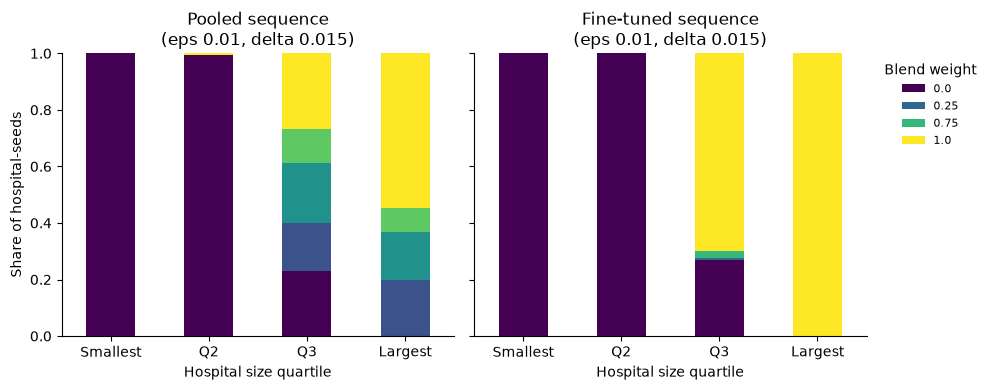

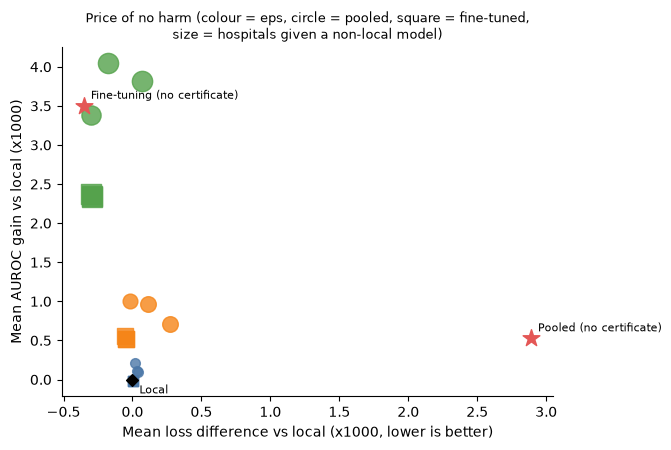

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]
C = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds}

def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

# F11: chosen blend by hospital size
big = pd.concat([C[s].assign(seed=s) for s in seeds], ignore_index=True).copy()
big["size_q"] = pd.qcut(big["n_train"], 4, labels=["Smallest", "Q2", "Q3", "Largest"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, src, title in zip(ax, ["pool", "ft"], ["Pooled sequence", "Fine-tuned sequence"]):
    tab = pd.crosstab(big["size_q"], big[f"cert_{src}_e0.01_d0.015__blend"], normalize="index")
    tab.plot(kind="bar", stacked=True, ax=a, colormap="viridis", legend=False)
    a.set_title(title + "\n(eps 0.01, delta 0.015)"); a.set_xlabel("Hospital size quartile"); a.tick_params(axis="x", rotation=0)
ax[0].set_ylabel("Share of hospital-seeds")
ax[1].legend(title="Blend weight", frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
save("fig11_chosen_blend")

# F12: price of no harm over the 3 x 3 grid
rows = []
for src in ("pool", "ft"):
    for eps in [0.005, 0.01, 0.02]:
        for delta in [0.01, 0.015, 0.02]:
            pre = f"cert_{src}_e{eps}_d{delta}"
            rows.append((src, eps, delta, np.mean([(C[s][f"{pre}__blend"] > 0).sum() for s in seeds]),
                         1000 * np.mean([C[s][f"{pre}__diff"].mean() for s in seeds]),
                         1000 * np.mean([(C[s][f"{pre}__auroc"] - C[s]["local__auroc"]).mean() for s in seeds])))
P = pd.DataFrame(rows, columns=["sequence", "eps", "delta", "n_nonlocal", "loss_x1000", "auroc_x1000"])
P.to_csv("../outputs/tables/F12_price_of_no_harm_grid.csv", index=False)

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ecol = {0.005: "#4C78A8", 0.01: "#F58518", 0.02: "#54A24B"}
for _, r in P.iterrows():
    ax.scatter(r["loss_x1000"], r["auroc_x1000"], s=15 + 2 * r["n_nonlocal"], c=ecol[r["eps"]],
               marker="o" if r["sequence"] == "pool" else "s", alpha=0.8)
for name, pre in [("Pooled (no certificate)", "pool_full"), ("Fine-tuning (no certificate)", "ft_full")]:
    x_ = 1000 * np.mean([C[s][f"{pre}__diff"].mean() for s in seeds])
    y_ = 1000 * np.mean([(C[s][f"{pre}__auroc"] - C[s]["local__auroc"]).mean() for s in seeds])
    ax.scatter(x_, y_, marker="*", s=160, c="#E45756"); ax.annotate(name, (x_, y_), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.scatter(0, 0, marker="D", c="k"); ax.annotate("Local", (0, 0), fontsize=8, xytext=(5, -10), textcoords="offset points")
ax.set_xlabel("Mean loss difference vs local (x1000, lower is better)"); ax.set_ylabel("Mean AUROC gain vs local (x1000)")
ax.set_title("Price of no harm (colour = eps, circle = pooled, square = fine-tuned,\nsize = hospitals given a non-local model)", fontsize=9)
save("fig12_price_of_no_harm")